In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import abc, gc, os, random, re, sys, time, traceback
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stable_baselines3 as sb
from stable_baselines3.common.env_util import make_vec_env
from typing import SupportsFloat, Any
import gymnasium as gym
from gymnasium.core import ActType, ObsType

import faiss
import sklearn
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import chime
import scipy.sparse as sp

import torch
from torch.nn import functional as F
from torch.utils import data
from torch import optim

In [3]:
from data_loaders import KuaiRecData, commit_dataset, CommitedDataset, JaggedCommittedDataset, commit_dataset_jagged
from dl_trainer import Trainer, sequence_collate, create_sequence_collator
from rs_algorithm.models import AdaptiveRepresentation
from rs_algorithm.models import TwoTowerRecommender, ThreeTowerRecommenderV2, ConcatInteractionHistoryRepresentationWithUserEmbedInitialization
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel, norm_dot_product_based_relavance_calculation, SimUserModel
from rs_algorithm import DSHCRSSolution, AlternatingLeastSquaresBaseline, Evaluator, SimulationEvaluator

In [4]:
from implicit.als import AlternatingLeastSquares

In [5]:
data_model = KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [6]:
ratings, _ = train_test_split(data_model.ratings, train_size=0.1, stratify=data_model.ratings['user_id'])
# ratings = data_model.ratings
ratings: pd.DataFrame

In [7]:
solution = DSHCRSSolution(data_model, os.path.join('temp', 'checkpoints'))
solution.prepare()

In [8]:
user_ids = ratings['user_id'].unique()

In [9]:
users: dict[int, SimUserModel] = {}

with torch.no_grad():
    for uid in user_ids:
        uft = data_model.get_user_features(uid)
        solution.user_model.eval()
        uem, ubs = solution.user_model(
            torch.tensor([uid], dtype=torch.int64),
            torch.tensor(uft, dtype=torch.float32), )
        users[uid] = SimUserModel(
            uem.cpu().numpy(), ubs.cpu().numpy(),
            relevance_calculator=norm_dot_product_based_relavance_calculation,
            preference_update_manager=solution.norm_press_preference,
        )

In [10]:
_uid = next(iter(users.keys()))
_int = users[_uid].react(datetime.now(), None, np.random.rand(1, 128), None)
users[_uid].reset()
print(_int)

False


In [11]:
interactions = ratings[['user_id', 'item_id']]

In [12]:
column = []

for sample in tqdm(interactions.itertuples(), total=len(interactions)):
    uid, iid = sample.user_id, sample.item_id
    solution.item_model.eval()
    iem, ibs = solution.item_model(
        torch.tensor([iid], dtype=torch.int64),
        torch.tensor(data_model.get_item_features(iid), dtype=torch.float32))
    iem, ibs = iem.cpu().numpy(), ibs.cpu().numpy()
    users[uid].react(datetime.now(), None, iem, ibs)
    column.append(users[uid]._relevance)
    users[uid].reset()

interactions['rating'] = column
del column

100%|██████████| 99810/99810 [00:46<00:00, 2140.55it/s]


In [13]:
interactions['rating'] = interactions['rating'].astype(np.float32)

In [14]:
# T0 Interactions
data_model.ratings = interactions

In [130]:
solution = AlternatingLeastSquaresBaseline(data_model)
solution.prepare()

  0%|          | 0/15 [00:00<?, ?it/s]

In [16]:
evaluator = Evaluator()

In [17]:
evaluator.evaluate(solution)

{'train': {'hit_rate_at_k': np.float64(0.99),
  'precision_at_k': np.float64(0.56),
  'recall_at_k': np.float64(0.21231588492201972),
  'ndcg_at_k': np.float64(0.6092604820253947),
  'mrr_at_k': np.float64(0.8781666666666667)},
 'test': {'hit_rate_at_k': np.float64(0.03),
  'precision_at_k': np.float64(0.0030000000000000005),
  'recall_at_k': np.float64(0.004206349206349207),
  'ndcg_at_k': np.float64(0.005028074817820014),
  'mrr_at_k': np.float64(0.01583333333333333)}}

In [119]:
sim_evaluator = SimulationEvaluator(data_model, n_sample_users=1)

In [120]:
for u in sim_evaluator.sample_users:
    sim_evaluator.sample_users[u].fatigue_timeout_days = timedelta(days=1)
    sim_evaluator.sample_users[u]._state_vector['fatigue_timeout_days'] = timedelta(days=1)

In [131]:
results = sim_evaluator.evaluate_simulation(solution, n_time_stamps=1000, top_k=10)

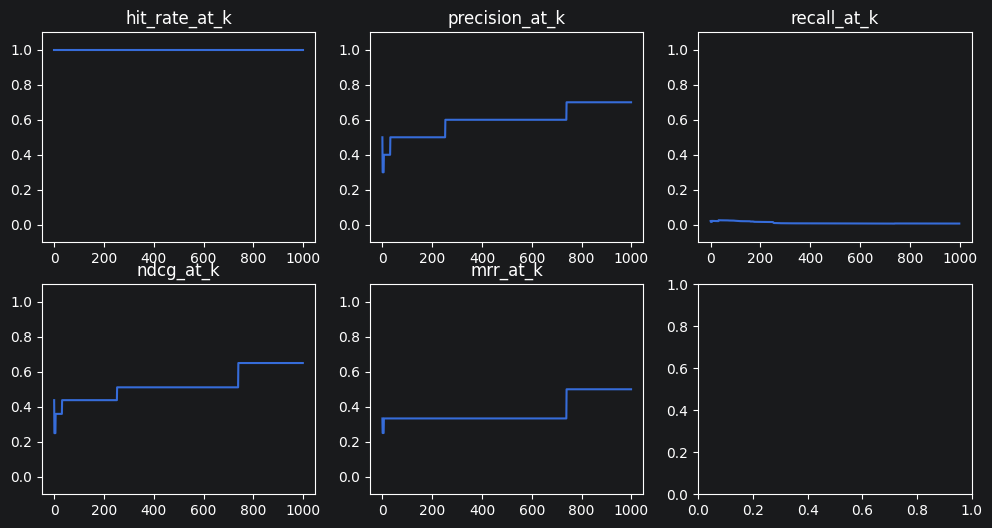

In [132]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, (k, v) in zip(axs.ravel(), results[0].items()):
    ax.plot(v)
    ax.set_title(k)
    ax.set_ylim(-0.1, 1.1)

In [112]:
aggregate = {'hit_rate_at_k': [],
             'precision_at_k': [],
             'recall_at_k': [],
             'ndcg_at_k': [],
             'mrr_at_k': []}

for t in range(1000):
    for m in ['hit_rate_at_k', 'precision_at_k', 'recall_at_k', 'ndcg_at_k', 'mrr_at_k']:
        aggregate[m].append(np.mean([r[m][t] for r in results]))

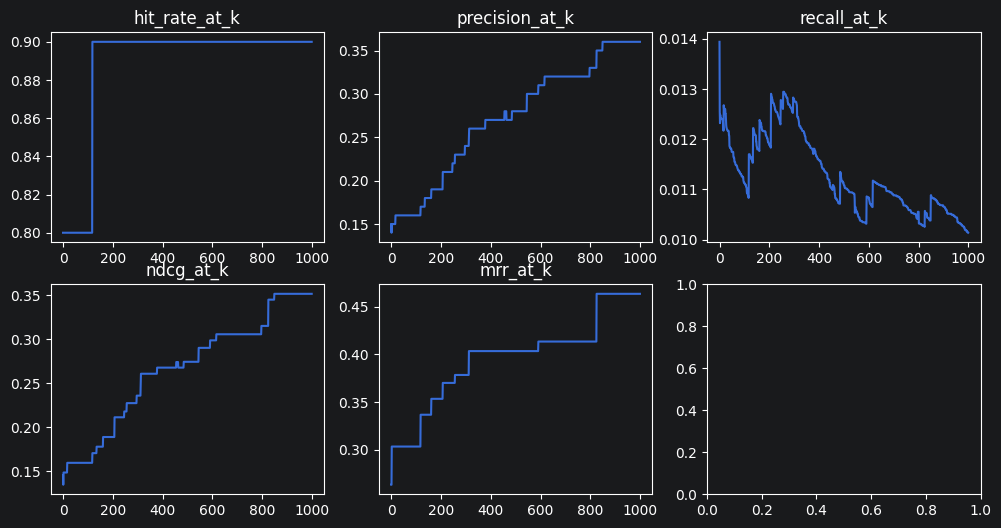

In [116]:
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, (k, v) in zip(axs.ravel(), aggregate.items()):
    ax.plot(v)
    ax.set_title(k)
    # ax.set_ylim(-0.1, 1.1)